# Visualize Inverse Kinemtics 2 link (elbow up)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math

init_theta1 = None
init_theta2 = None

## inverse_kinematics_2link

In [3]:
def inverse_kinematics_2link(L1, L2, theta1_min, theta1_max, theta2_min, theta2_max, target_end_effector_pos):
    global init_theta1, init_theta2
    
    x, y = target_end_effector_pos
    
    # Check if y-coordinate is non-negative
    if y < 0:
        return "Error: Y-coordinate must be greater than or equal to 0."

    d2 = x**2 + y**2
    d = np.sqrt(d2)

    base_angle = np.arctan2(y, x)

    # Cosine of the first angle in a triangle defined by L1 and L2
    C = (L1**2 + d2 - L2**2) / (2 * L1 * d)
    c = np.arccos(C)

    # Check if the target is reachable
    if not -1 <= C <= 1:
        return "Error: Target is outside the reachable workspace."

    # Cosine of the second angle
    B = (L1**2 + L2**2 - d2) / (2 * L1 * L2)
    b = np.arccos(B)

    # Calculate joint angles for elbow up configuration
    theta1_elbow_up = base_angle + c
    theta2_elbow_up = b - np.pi

    # Check if elbow up joint angles are within specified limits
    if (theta1_min <= theta1_elbow_up <= theta1_max) and (theta2_min <= theta2_elbow_up <= theta2_max):
        init_theta1 = theta1_elbow_up
        init_theta2 = theta2_elbow_up
        return

    # Calculate joint angles for elbow down configuration
    theta1_elbow_down = base_angle - c
    theta2_elbow_down = np.pi - b

    # Check if elbow down joint angles are within specified limits
    if (theta1_min <= theta1_elbow_down <= theta1_max) and (theta2_min <= theta2_elbow_down <= theta2_max):
        init_theta1 = theta1_elbow_down
        init_theta2 = theta2_elbow_down
        return

    return "Error: No valid joint angles found within the specified limits."

## Plot Function

In [4]:
def plot_manipulator(L1, L2, theta1, theta2):
    # Calculate joint positions
    x1 = L1 * np.cos(theta1)
    y1 = L1 * np.sin(theta1)
    x2 = x1 + L2 * np.cos(theta1 + theta2)
    y2 = y1 + L2 * np.sin(theta1 + theta2)

    # Plot manipulator
    plt.figure(figsize=(8, 6))
    plt.plot([0, x1], [0, y1], 'b-', linewidth=2, label='Link 1')
    plt.plot([x1, x2], [y1, y2], 'r-', linewidth=2, label='Link 2')
    plt.plot(0, 0, 'ko')  # Base
    plt.plot(x1, y1, 'ko')  # Joint 1
    plt.plot(x2, y2, 'ko')  # End effector
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('2-Link Manipulator Configuration')
    plt.axis('equal')
    plt.grid(True)
    plt.legend()
    plt.show()

## Inputs

Joint angles: 0.18736390816130827 -0.3607708359845989


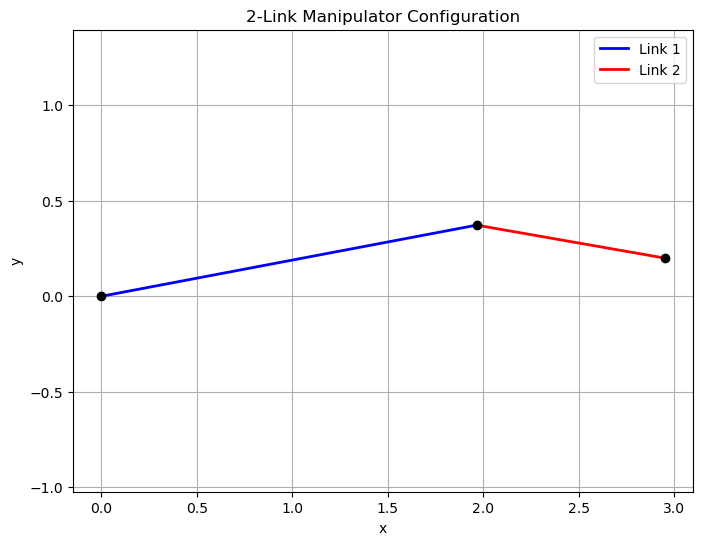

In [12]:
# Example usage

target_pos = (2.95, 0.2)
# target_pos = (1.3, 1.4)
L1 = 2
L2 = 1

#radians
theta1_min = 0
theta1_max = math.pi/2
theta2_min = -math.pi 
theta2_max = math.pi

result = inverse_kinematics_2link(L1, L2, theta1_min, theta1_max, theta2_min, theta2_max, target_pos)

if isinstance(result, str):
    print(result)
else:
    print("Joint angles:", init_theta1, init_theta2)
    # Plot the manipulator configuration
    plot_manipulator(L1, L2, init_theta1, init_theta2)

In [14]:
import numpy as np
import math
class Dynamics:
    def __init__(self):
        self.M1 = 6
        self.M2 = 3
        self.L1 = 2
        self.L2 = 1
        self.g = 9.81
    def calc_theta_ddot_frame(self, thetas, taus):
        th1 = thetas[0]
        th2  = thetas[1]
        thd1 = thetas[2]
        thd2 = thetas[3] 

        ta0 = taus[0]
        ta1 = taus[1]

        # frame_M_inv = MX.sym('frame_M_inv', 2, 2)
        # frame_c     = MX.sym('frame_c'    , 2)
        # frame_G     = MX.sym("frame_G"    , 2)

        a   = (self.M1 + self.M2) * self.L1**2 #scalar
        d   = self.M2 * self.L2**2 #scalar

        b_c = self.M2 * self.L1 * self.L2 * math.cos(th1 - th2) #scalar

        # M_inv matrix, invertible iff masses and lengths are non-zero
        determinant = a * d - b_c ** 2 #scalar

        M_i_00 = d     / determinant #scalar
        M_i_01 = -b_c  / determinant
        M_i_10 = -b_c  / determinant
        M_i_11 = a     / determinant
        # frame_M_inv = vertcat(horzcat(d / determinant, -b_c / determinant), horzcat(-b_c / determinant, a / determinant))


        common = self.M2 * self.L1 * self.L2 * math.sin(th1 - th2) #scalar
        c_0 =  common * thd1**2
        c_1 = -common * thd2**2
        # frame_c = vertcat(common * thd1**2, -common * thd2**2)


        G_0 = (self.M1+self.M2) * self.g * self.L1 * math.cos(th1) #scalar
        G_1 = self.M2 * self.g * self.L2 * math.cos(th2) #scalar

        # frame_G = vertcat((self.M1 + self.M2) * self.g * self.L1 * cos(th1), self.M2 * self.g * self.L2 * cos(th2))


        # B = taus - frame_c - frame_G
        B0 = ta0 - c_0 - G_0
        B1 = ta1 - c_1 - G_1

        acc1 = M_i_00 * B0 + M_i_01 * B1
        acc2 = M_i_10 * B0 + M_i_11 * B1

        
        return np.array([[acc1],
                         [acc2]])
    

    def accel_np(self, thetas, taus):
        th1, th2, thd1, thd2 = thetas
        ta0, ta1 = taus
        M = np.array([[(self.M1 + self.M2) * self.L1**2, self.M2 * self.L1 * self.L2 * math.cos(th1 - th2)],
                      [self.M2 * self.L1 * self.L2 * math.cos(th1 - th2), self.M2 * self.L2**2]])
        
        common = self.M2 * self.L1 * self.L2 * math.sin(th1 - th2) #scalar
        c = np.array([[common * thd1**2],
                      [-common * thd2**2]])
        G = np.array([[(self.M1+self.M2) * self.g * self.L1 * math.cos(th1)],
                        [self.M2 * self.g * self.L2 * math.cos(th2)]])
        M_inv = np.linalg.inv(M)
        print("taus ",taus, "\n c ", c, "\n G ",G)
        thdd = M_inv @ (taus - c - G).reshape(2,1)
        return thdd
        
thetas = [0.1873639, -0.36077, 0.0, 0.0]
taus = np.array([30, 40]).reshape(2,1)

dyn = Dynamics()

print(" first", dyn.calc_theta_ddot_frame(thetas, taus), 
      '\n\n')
print(dyn.accel_np(thetas, taus))

 first [[[-6.04459703]]

 [[14.47295726]]] 


taus  [[30]
 [40]] 
 c  [[ 0.]
 [-0.]] 
 G  [[173.48961576]
 [ 27.53545243]]
[[-6.04459703]
 [14.47295726]]
